# TMDB Sentiment-Based Movie Recommender — **MINI-PROJECT**

> 📖 **Read [`PROJECT_BRIEF.md`](PROJECT_BRIEF.md) before you start.** It contains the full requirements, the rubric, and the function specification you must implement.

**Effort:** ~6–8 hours · **Stack:** pandas, numpy, scikit-learn, nltk (VADER), textblob — **no transformers, no GPU**

---

## What you are building

A content-based movie recommender that ranks the TMDB 5000 catalogue by combining **two signals**:

1. **Topic similarity** — TF-IDF cosine between your query and each movie's plot overview (from C2)
2. **Mood match** — proximity between your target mood and the VADER compound score of the overview (from C3)

Final score per movie:

$$\text{score} = w_{\text{content}} \cdot \text{cos\_sim}(q, m) + w_{\text{mood}} \cdot \text{mood\_match}(q, m)$$

## Important framing

The TMDB dataset has **no user reviews** — only marketing-written plot overviews. So "sentiment analysis" here doesn't mean classifying reviews as positive/negative. It means **extracting mood/tone from a plot summary** (dark, hopeful, tragic, romantic) and using that as a recommendation signal. Don't fight that framing — discuss its limits in §9.

## How to use this notebook

- Each section has a header showing its **rubric weight**
- Run the **setup cells (§1)** as-is — they're provided for you
- Fill in every cell marked with `# TODO:` — that's where the work is
- Markdown cells with `> ✏️ **Your discussion:**` are written-answer questions
- Use **Run All** to verify your notebook executes top-to-bottom before submitting

## S1 — Setup & Data Loading  *(provided, just run it)*

In [109]:
import json
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# NLTK data needed for tokenization, stop words, and lemmatization
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(pkg, quiet=True)

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
%matplotlib inline

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

In [110]:
# Load both CSVs from the bundled dataset folder
MOVIES_PATH = '../../00-data/tmdb_5000_movies.csv'
CREDITS_PATH = '../../00-data/tmdb_5000_credits.csv'

movies_df = pd.read_csv(MOVIES_PATH)
credits_df = pd.read_csv(CREDITS_PATH)

print(f'movies:  {movies_df.shape}')
print(f'credits: {credits_df.shape}')
movies_df.head(2)

movies:  (4803, 20)
credits: (4803, 4)


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500


In [111]:
# Drop rows where overview is missing and reset the index.
# Resetting the index is critical - later, .iloc[i] must align with the TF-IDF matrix you build.
movies_df = movies_df.dropna(subset=['overview']).reset_index(drop=True)
print(f'after dropping missing overviews: {movies_df.shape}')

after dropping missing overviews: (4800, 20)


## S2 — Exploratory Data Analysis  *

Build a quick understanding of the data before you model. You need three things:

1. Distribution of `vote_average`
2. Top 10 genres (the `genres` column is a JSON string — you'll need `json.loads`)
3. Word-count distribution of the `overview` field

In [112]:
from ast import literal_eval

In [113]:
df = movies_df.copy()

In [114]:
df['genres_parsed'] = df['genres'].apply(literal_eval)

In [115]:

df['genres_parsed'] = df['genres_parsed'].apply(lambda x: [d['name'] for d in x])

In [116]:
df[df['genres_parsed'].apply(lambda x: 'Horror' in x)]

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count,genres_parsed
45,200000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 18, ""nam...",http://www.worldwarzmovie.com,72190,"[{""id"": 4565, ""name"": ""dystopia""}, {""id"": 1233...",en,World War Z,Life for former United Nations investigator Ge...,81.834855,"[{""name"": ""Paramount Pictures"", ""id"": 4}, {""na...",...,2013-06-20,531865000,116.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,Remember Philly!,World War Z,6.7,5560,"[Action, Drama, Horror, Science Fiction, Thril..."
97,15000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",NaN,315011,"[{""id"": 1299, ""name"": ""monster""}, {""id"": 7671,...",ja,シン・ゴジラ,From the mind behind Evangelion comes a hit la...,9.476999,"[{""name"": ""Cine Bazar"", ""id"": 5896}, {""name"": ...",...,2016-07-29,77000000,120.0,"[{""iso_639_1"": ""it"", ""name"": ""Italiano""}, {""is...",Released,A god incarnate. A city doomed.,Shin Godzilla,6.5,143,"[Action, Adventure, Drama, Horror, Science Fic..."
116,150000000,"[{""id"": 18, ""name"": ""Drama""}, {""id"": 27, ""name...",http://iamlegend.warnerbros.com/,6479,"[{""id"": 83, ""name"": ""saving the world""}, {""id""...",en,I Am Legend,Robert Neville is a scientist who was unable t...,70.867401,"[{""name"": ""Village Roadshow Pictures"", ""id"": 7...",...,2007-12-14,585349010,101.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The last man on Earth is not alone,I Am Legend,6.9,4853,"[Drama, Horror, Action, Thriller, Science Fict..."
135,150000000,"[{""id"": 18, ""name"": ""Drama""}, {""id"": 27, ""name...",http://www.thewolfmanmovie.com/,7978,"[{""id"": 494, ""name"": ""father son relationship""...",en,The Wolfman,"Lawrence Talbot, an American man on a visit to...",21.214571,"[{""name"": ""Universal Pictures"", ""id"": 33}, {""n...",...,2010-02-11,0,102.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,When the moon is full the legend comes to life,The Wolfman,5.5,549,"[Drama, Horror, Thriller]"
217,110000000,"[{""id"": 53, ""name"": ""Thriller""}, {""id"": 28, ""n...",http://www.sonypictures.com/movies/ghostrider/,1250,"[{""id"": 2870, ""name"": ""mephisto""}, {""id"": 3684...",en,Ghost Rider,"In order to save his dying father, young stunt...",46.834704,"[{""name"": ""Columbia Pictures Corporation"", ""id...",...,2007-02-16,228738393,114.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,Hell Is About To Be Unleashed,Ghost Rider,5.2,1712,"[Thriller, Action, Fantasy, Horror]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4780,0,"[{""id"": 53, ""name"": ""Thriller""}, {""id"": 27, ""n...",NaN,226458,"[{""id"": 9712, ""name"": ""possession""}]",en,Backmask,"During an all-night, drug-fueled party at an a...",3.619167,"[{""name"": ""GO Productions"", ""id"": 2943}, {""nam...",...,2015-01-16,0,91.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,nederlands,Backmask,4.7,79,"[Thriller, Horror]"
4785,12000,"[{""id"": 27, ""name"": ""Horror""}, {""id"": 35, ""nam...",NaN,692,"[{""id"": 237, ""name"": ""gay""}, {""id"": 900, ""name...",en,Pink Flamingos,Notorious Baltimore criminal and underground f...,4.553644,"[{""name"": ""Dreamland Productions"", ""id"": 407}]",...,1972-03-12,6000000,93.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,An exercise in poor taste.,Pink Flamingos,6.2,110,"[Horror, Comedy, Crime]"
4788,13,"[{""id"": 27, ""name"": ""Horror""}]",http://tincanmanthemovie.com/,157185,"[{""id"": 14903, ""name"": ""home invasion""}]",en,Tin Can Man,Recently dumped by his girlfirend for another ...,0.332679,"[{""name"": ""Park Films"", ""id"": 21871}, {""name"":...",...,2007-01-01,0,84.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,Everything You've Heard is True,Tin Can Man,2.0,1,[Horror]
4789,200

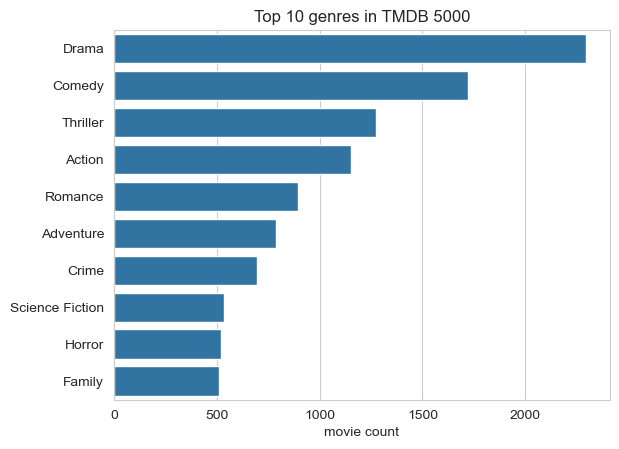

In [117]:
genre_counts = Counter(g for sub in df['genres_parsed'] for g in sub)
top_genres = genre_counts.most_common(10)
sns.barplot(x = [c for _,c in top_genres],y=[g for g,_ in top_genres])
plt.title('Top 10 genres in TMDB 5000')
plt.xlabel('movie count')
plt.show()

In [118]:
df.columns

Index(['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language',
       'original_title', 'overview', 'popularity', 'production_companies',
       'production_countries', 'release_date', 'revenue', 'runtime',
       'spoken_languages', 'status', 'tagline', 'title', 'vote_average',
       'vote_count', 'genres_parsed'],
      dtype='object')

<Axes: xlabel='vote_average', ylabel='Count'>

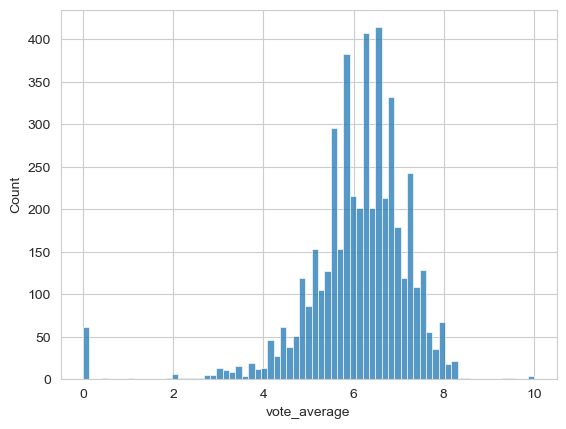

In [119]:
# TODO: Plot the distribution of vote_average using sns.histplot.
# Hint: bins=30, kde=True is a sensible starting point.
# Also print movies_df['vote_average'].describe() to see the summary stats.
sns.histplot(data=df,x='vote_average')

In [120]:
# TODO: Build a parse_genre_names(genres_json) function that returns a list of genre names.
# Hint: each row of movies_df['genres'] is a JSON string like:
#       '[{"id": 28, "name": "Action"}, {"id": 12, "name": "Adventure"}]'
# Use json.loads() to decode it. Wrap in try/except so a malformed row returns [].
#
# Then:
#   - apply it to create a 'genre_list' column
#   - flatten all genres into a single list
#   - use collections.Counter to find the top 10
#   - plot them as a horizontal bar chart


In [121]:
# TODO: Compute and plot the distribution of overview lengths (word count).
# Hint: movies_df['overview'].str.split().str.len() gives you words per overview.
# Save it as a column 'overview_word_count' so you can reuse it.


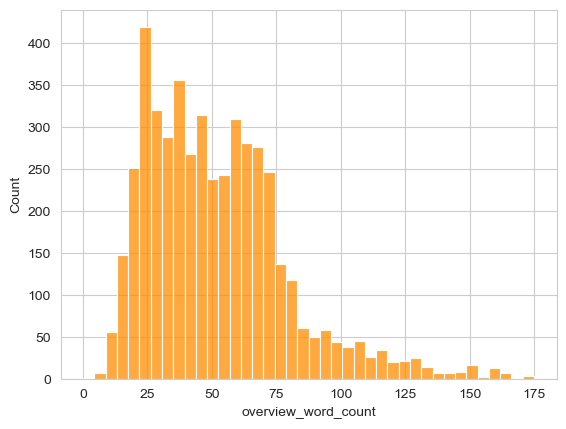

In [122]:
df['overview_word_count'] = df['overview'].str.split().str.len()
sns.histplot(df['overview_word_count'],bins=40,color='darkorange')
plt.show()

In [123]:
df['overview_word_count'].describe()

count    4800.000000
mean       52.157292
std        27.867016
min         0.000000
25%        30.000000
50%        48.000000
75%        67.000000
max       175.000000
Name: overview_word_count, dtype: float64

> ✏️ **Your EDA takeaway (1–2 sentences):** What does the data look like? Anything that will affect your modeling decisions later?

*Write your answer here...*

## S3 — Text Preprocessing  
You need a single `clean_text` function you'll call on **both** movie overviews (now) and on user queries (in §6). Using the same function for both is critical — if you preprocess differently in the two places, your cosine similarities will be garbage.

**Required pipeline:** lowercase → strip non-letters → tokenize → drop stop words → lemmatize

**Discussion question:** why lemmatize but not stem? Why drop stop words at all? Answer in the markdown cell after the function.

In [124]:
_lemmatizer = WordNetLemmatizer()
_stop_words = set(stopwords.words('english'))

def clean_text(text: str) -> str:
    """Lowercase, strip non-letters, tokenize, drop stop words, lemmatize.
    Returns a single space-joined string suitable for TfidfVectorizer."""
    # TODO: implement the cleaning pipeline.
    # 1. handle the empty/None case - return '' if text is missing
    # 2. lowercase
    # 3. use re.sub to keep only letters and whitespace
    # 4. tokenize with word_tokenize
    # 5. drop tokens that are in _stop_words OR have length <= 2
    # 6. lemmatize each surviving token with _lemmatizer.lemmatize
    # 7. return ' '.join(tokens)
    if not isinstance(text,str) or not text.strip():
        return ''
    text = text.lower()
    text = re.sub(r"[^a-z\s]", ' ',text)
    tokens = word_tokenize(text)
    tokens = [_lemmatizer.lemmatize(t) for t in tokens if t not in _stop_words and len(t)>2]
    return ' '.join(tokens)

# Smoke test - this should print a cleaned version of the first overview
sample = movies_df['overview'].iloc[0]
print('ORIGINAL:', sample[:200])
print('CLEANED :', clean_text(sample)[:200] if clean_text(sample) else '(empty - did you implement clean_text?)')

ORIGINAL: In the 22nd century, a paraplegic Marine is dispatched to the moon Pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization.
CLEANED : century paraplegic marine dispatched moon pandora unique mission becomes torn following order protecting alien civilization


In [126]:
# TODO: apply clean_text to every overview and store the result in a new column 'clean_overview'.
# Then display the first 3 rows of [['title', 'clean_overview']] to confirm it worked.
df['clean_overview'] = df['overview'].apply(clean_text)

> ✏️ **Justify your preprocessing choices (3–4 sentences):** Why lemmatization over stemming? Why drop stop words? Why drop very short tokens? Did you make any other choices, and why?

*Write your answer here...*

## S4 — Sentiment Scoring  
Compute **two** sentiment scores per movie and store them as columns:

- `vader_compound` — your primary mood signal (used by the recommender in §6)
- `textblob_polarity` — kept for the comparison/sanity-check exercise

Run both on the **original** (uncleaned) overview text. VADER cares about capitalization and punctuation; TextBlob cares about sentence structure. Cleaning would erase that signal.

In [127]:
vader = SentimentIntensityAnalyzer()

# TODO: write two helper functions:
#   def vader_compound(text: str) -> float: ...
#   def textblob_polarity(text: str) -> float: ...
# Then add two new columns to movies_df: 'vader_compound' and 'textblob_polarity'.
# Hint: vader.polarity_scores(text)['compound'] and TextBlob(text).sentiment.polarity
vader = SentimentIntensityAnalyzer()

def vader_compund(text: str)-> float:
    return vader.polarity_scores(text)['compound']

def textblob_polarity(text: str)-> float:
    return TextBlob(text).sentiment.polarity

# Display the first 5 rows of [title, vader_compound, textblob_polarity] when done
df['vader_compound'] = df['overview'].apply(vader_compund)
df['textblob_polarity'] = df['overview'].apply(textblob_polarity)

In [128]:
# TODO: plot side-by-side histograms of vader_compound and textblob_polarity.
# Use plt.subplots(1, 2, ...) so they sit next to each other.
# Also print:
#   - the mean of each column
#   - the Pearson correlation between the two columns


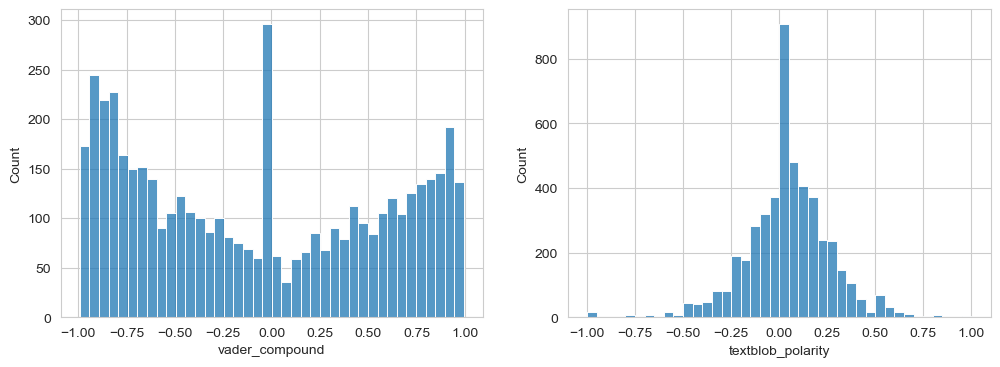

In [129]:
# TODO: find movies where the two methods disagree strongly.
# Filter for: vader_compound > 0.6 AND textblob_polarity < -0.2
# Print how many you found and show the first 3 rows with title + scores + overview.
fig,axes = plt.subplots(1,2,figsize=(12,4))
sns.histplot(df['vader_compound'],bins=40,ax=axes[0])

sns.histplot(df['textblob_polarity'],bins=40,ax=axes[1])

plt.show()

In [130]:
conflict = df[(df['vader_compound']>0.6) & (df['textblob_polarity']<-0.2)]
len(conflict)

12

In [131]:
conflict[['title','vader_compound','textblob_polarity','overview']]

,title,vader_compound,textblob_polarity,overview
143,Pan,0.9451,-0.212727,Living a bleak existence at a London orphanage...
365,Contact,0.6369,-0.375000,Contact is a science fiction film about an enc...
473,Mars Attacks!,0.7766,-0.256250,'We come in peace' is not what those green men...
692,Chicken Little,0.9026,-0.375000,When the sky really is falling and sanity has ...
1557,Million Dollar Baby,0.7019,-0.700000,Despondent over a painful estrangement from hi...
1746,Welcome Home Roscoe Jenkins,0.9229,-0.277500,"Martin Lawrence leads an all-star cast, includ..."
2352,Catch That Kid,0.8126,-0.212500,Athletic 12-year-old Maddy (Kristen Stewart) s...
2948,The Guru,0.9598,-0.500000,Bored with Bollywood movies but fascinated wit...
2980,She's All That,0.9684,-0.246333,High school hotshot Zach Siler is the envy of ...
3076,Malone,0.6059,-0.233333,Erstwhile C.I.A. assassin Richard Malone hopes...


In [132]:
for x in conflict[['title','vader_compound','textblob_polarity','overview']]['overview']:
    print(x)
    print('x'*100)

Living a bleak existence at a London orphanage, 12-year-old Peter finds himself whisked away to the fantastical world of Neverland. Adventure awaits as he meets new friend James Hook and the warrior Tiger Lily. They must band together to save Neverland from the ruthless pirate Blackbeard. Along the way, the rebellious and mischievous boy discovers his true destiny, becoming the hero forever known as Peter Pan.
xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx
Contact is a science fiction film about an encounter with alien intelligence. Based on the novel by Carl Sagan the film starred Jodie Foster as the one chosen scientist who must make some difficult decisions between her beliefs, the truth, and reality.
xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx
'We come in peace' is not what those green men from Mars mean when they invade our planet, armed with irresistible weapons and a cr

> ✏️ **Discussion (4–6 sentences):** Where do VADER and TextBlob disagree most? Pick one of the conflict examples above and explain *why* the two methods give different scores. Which one would you trust more for movie overviews, and why?

*Write your answer here...*

## S5 — TF-IDF Vectorization  
Fit a `TfidfVectorizer` on your `clean_overview` column. You need to choose sensible parameters and **justify them in writing** — there are no single right answers, but there are wrong ones.

**Parameters to think about:**

- `max_features` — how big do you want the vocabulary?
- `ngram_range` — unigrams only, or also bigrams?
- `min_df` — drop terms that appear in fewer than how many docs?
- `max_df` — drop terms that appear in more than what fraction of docs?
- `sublinear_tf` — true or false?

In [133]:
# TODO: instantiate a TfidfVectorizer with parameters you can justify.
# Then fit_transform it on movies_df['clean_overview'] and store the result as `tfidf_matrix`.
# Print the shape of the matrix and the vocabulary size.

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,ngram_range=(1,2),min_df=2,max_df=0.85,
)
tfidf_matrix = tfidf_vectorizer.fit_transform(df['clean_overview'])      # TODO


In [134]:
len(tfidf_vectorizer.vocabulary_)

5000

In [135]:
# TODO: write a helper top_tfidf_features(movie_index, n=10) that returns a DataFrame
# with the top n TF-IDF features for one specific movie.
# Hint: tfidf_matrix[movie_index].toarray().flatten() gives you the row.
# Use tfidf_vectorizer.get_feature_names_out() to map indices to words.
#
# Then call it for movies_df.iloc[0] (the first movie) and print the top 10 features.
def top(movie_index,n=10):
    row = tfidf_matrix[movie_index].toarray().flatten()
    feature_names = tfidf_vectorizer.get_feature_names_out()
    top_idx = row.argsort()[::-1][:n]
    return pd.DataFrame({'feature':feature_names[top_idx],'tfidf':row[top_idx].round(3)})

In [136]:
print(df['title'].iloc[10])
print(df['overview'].iloc[10])
top(10)

Superman Returns
Superman returns to discover his 5-year absence has allowed Lex Luthor to walk free, and that those he was closest too felt abandoned and have moved on. Luthor plots his ultimate revenge that could see millions killed and change the face of the planet forever, as well as ridding himself of the Man of Steel.


,feature,tfidf
0,luthor,0.522
1,superman,0.245
2,absence,0.245
3,steel,0.227
4,moved,0.215
5,walk,0.209
6,abandoned,0.198
7,ultimate,0.192
8,forever,0.177
9,million,0.175


> ✏️ **Justify your TF-IDF parameters (3–5 sentences):** Why these `max_features`, `ngram_range`, `min_df`, and `max_df` values? What would change if you doubled `max_features`? What would change if you used unigrams only?

*Write your answer here...*

## S6 — Build the Recommender  
Now you implement the function the whole project has been building toward. Read [`PROJECT_BRIEF.md`](PROJECT_BRIEF.md) §5 for the exact specification.

**Two helpers, then the main function.**

### Hints (read these first)

1. **Vectorise the query with the SAME fitted `tfidf_vectorizer`.** Use `vectorizer.transform([query])` — never `fit_transform`. If you call `fit_transform` you destroy the vocabulary.
2. **Clean the query first.** Call `clean_text(query)` before passing it to the vectorizer, otherwise the query and the corpus are in different spaces.
3. **`cosine_similarity(query_vec, tfidf_matrix)`** does the whole-corpus comparison in one call. No Python loop needed.
4. **`mood_match(target, movie_mood)` should return `1 - abs(target - movie_mood) / 2`** so the mood term lives on the same `[0, 1]` scale as cosine similarity.
5. **The final score is `w_content * similarity + w_mood * mood_match`.** That's it.
6. **Return a DataFrame with columns: `title, score, similarity, mood_match, vote_average, overview`** (see the spec).

In [137]:
df.columns

Index(['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language',
       'original_title', 'overview', 'popularity', 'production_companies',
       'production_countries', 'release_date', 'revenue', 'runtime',
       'spoken_languages', 'status', 'tagline', 'title', 'vote_average',
       'vote_count', 'genres_parsed', 'overview_word_count', 'clean_overview',
       'vader_compound', 'textblob_polarity'],
      dtype='object')

In [138]:
def mood_match(target: float, movie_mood: np.ndarray) -> np.ndarray:
    """Rescale 1 - |a - b| from [0, 2] down to [0, 1] so it matches cosine similarity scale."""
    # TODO: one line. See the formula in the hints above.
    return 1.0 - np.abs(target-movie_mood)/2.0

# def label_mood(d):
#     if abs(d) <=0.1: return 'on-mood'
#     if d>0.1 and d<= 0.4: return 'uplifting'
#     if d > 0.1: return 'comedy'
#     if d <=0.4: return 'gloomy'
#     return 'dark'

def recommend(query_text: str,
              target_mood: float,
              k: int = 10,
              w_content: float = 0.7,
              w_mood: float = 0.3) -> pd.DataFrame:
    """Hybrid TF-IDF + sentiment movie recommender. See PROJECT_BRIEF.md §5 for the spec."""
    # TODO: implement the function. Suggested steps:
    # 1. (Optional but encouraged) sanity-check that w_content + w_mood == 1
    # 2. clean and vectorize the query (clean_text + tfidf_vectorizer.transform)
    # 3. compute cosine similarities vs the whole tfidf_matrix
    # 4. compute mood match for the whole catalogue using your mood_match() helper
    # 5. combine: final_scores = w_content * similarities + w_mood * mood_scores
    # 6. take the top-k indices (np.argsort()[::-1][:k])
    # 7. build a result DataFrame with columns: title, score, similarity, mood_match, vote_average, overview
    # 8. truncate the overview column to ~120 chars + '...' so the table is readable
    if not np.isclose(w_content+w_mood,1.0):
        raise ValueError(f"w_content+w_mood must equal to 1.0 (got{w_content+w_mood})")
    clean_query = clean_text(query_text)
    query_vec = tfidf_vectorizer.transform([clean_query])
    similarities = cosine_similarity(query_vec,tfidf_matrix).flatten()
    mood_scores = mood_match(target_mood,df['vader_compound'].values)
    final_scores = w_content*similarities+w_mood* mood_scores
    top_idx = final_scores.argsort()[::-1][:k]
    result = df.iloc[top_idx][['title','vote_average', 'overview']].copy()
    result.insert(1,'score',final_scores[top_idx].round(3))
    result.insert(2,'similarity',similarities[top_idx].round(3))
    result.insert(3,'mood_match',mood_scores[top_idx].round(3))
    result['overview'] = result['overview'].str[:120] + "."
    return result.reset_index(drop=True)

## S7 — Try It Out  

Two queries are provided. Then you must add **at least 3 of your own** with a one-line comment about each one (what mood/topic you were aiming for).

In [104]:
# Provided query #1 - hopeful space adventure
recommend('lonely astronaut finds hope in space', target_mood=0.6, k=10)

,title,score,similarity,mood_match,vote_average,overview
0,The Right Stuff,0.492,0.335,0.859,7.3,A chronicle of the original Mercury astronauts...
1,Zathura: A Space Adventure,0.439,0.224,0.938,6.1,"After their father is called into work, two yo..."
2,Space Pirate Captain Harlock,0.438,0.232,0.920,6.5,Space Pirate Captain Harlock and his fearless ...
3,Silver Medalist,0.435,0.205,0.971,7.4,An action-adventure story focused on the lives...
4,Deck the Halls,0.417,0.190,0.948,5.1,Two neighbors have it out after one of them de...
5,Gattaca,0.412,0.168,0.982,7.5,Science fiction drama about a future society i...
6,The Chorus,0.387,0.127,0.994,7.5,"Set in 1940's France, a new teacher at a schoo..."
7,Planet 51,0.386,0.155,0.925,5.6,When Earth astronaut Capt. Chuck Baker arrives...
8,Special,0.385,0.142,0.950,6.6,A lonely metermaid has a psychotic reaction to...
9,Lifeforce,0.379,0.171,0.862,6.2,A space shuttle mission investigating Halley's...


In [105]:
# Provided query #2 - dark psychological thriller
recommend('dark psychological thriller with murder and obsession', target_mood=-0.5, k=10)

,title,score,similarity,mood_match,vote_average,overview
0,Enter the Dangerous Mind,0.470,0.264,0.950,4.8,A psychological thriller set in the world of u...
1,Circle,0.400,0.239,0.776,6.0,Could you trust a jury of your peers with your...
2,Mindhunters,0.396,0.168,0.926,6.3,Trainees in the FBI's psychological profiling ...
3,One Hour Photo,0.394,0.191,0.868,6.6,"Sy ""the photo guy"" Parrish has lovingly develo..."
4,8MM,0.393,0.162,0.932,6.1,"A small, seemingly innocuous plastic reel of f..."
5,Circumstance,0.389,0.159,0.926,7.4,A wealthy Iranian family struggles to contain ...
6,Hereafter,0.380,0.123,0.979,5.8,A supernatural thriller centered on three peop...
7,White Noise,0.378,0.150,0.909,5.6,An architect's desire to speak with his wife f...
8,The Sixth Sense,0.371,0.176,0.826,7.7,A psychological thriller about an eight year o...
9,A Civil Action,0.370,0.104,0.988,6.1,Jan Schlickmann is a cynical lawyer who goes o...


In [106]:
# TODO: Your query #1 - what were you hoping to retrieve?
# Comment on whether the results matched your expectation.
recommend('satanic cult horror ', target_mood=-0.5, k=10)


,title,score,similarity,mood_match,vote_average,overview
0,Martha Marcy May Marlene,0.487,0.331,0.853,6.7,"After several years of living with a cult, Mar..."
1,The Golden Child,0.469,0.331,0.791,5.6,A detective specializing in missing children i...
2,The Call of Cthulhu,0.466,0.397,0.626,6.9,A dying professor leaves his great-nephew a co...
3,Krampus,0.446,0.240,0.926,5.9,A horror comedy based on the ancient legend ab...
4,Tank Girl,0.439,0.220,0.951,5.5,"Based on the British cult comic-strip, our tan..."
5,Sound of My Voice,0.433,0.297,0.750,6.3,A journalist and his girlfriend get pulled in ...
6,Indiana Jones and the Temple of Doom,0.428,0.195,0.971,7.1,"After arriving in India, Indiana Jones is aske..."
7,Heavy Metal,0.420,0.243,0.834,6.2,A glowing orb terrorizes a young girl with a c...
8,Drive Angry,0.415,0.263,0.770,5.3,Milton is a hardened felon who has broken out ...
9,Diary of the Dead,0.413,0.176,0.964,5.4,A group of young film students run into real-l...


In [108]:
# TODO: Your query #2 - what were you hoping to retrieve?
# Comment on whether the results matched your expectation.
recommend('demonic possession poltegeist', target_mood=-0.5, k=10)


,title,score,similarity,mood_match,vote_average,overview
0,The Amityville Horror,0.500,0.312,0.938,6.0,A family is terrorized by demonic forces after...
1,The Ring Two,0.474,0.281,0.926,5.4,Rachel Keller must prevent evil Samara from ta...
2,The Unborn,0.472,0.299,0.875,4.8,A young woman fights the spirit that is slowly...
3,The Vatican Exorcisms,0.463,0.408,0.591,4.4,Documentary following US film-maker Joe Marino...
4,The Last Exorcism,0.461,0.245,0.966,5.6,After years of performing “exorcisms” and taki...
5,MacGruber,0.424,0.190,0.971,5.1,Ex-special operative MacGruber (Forte) is call...
6,AWOL-72,0.424,0.184,0.984,2.8,An AWOL marine in possession of secret governm...
7,Deliver Us from Evil,0.404,0.253,0.758,5.9,When a frightening wave of violence sweeps thr...
8,Reign of Assassins,0.376,0.114,0.987,6.7,"Set in ancient China, Zeng Jing is a skilled a..."
9,The Evil Dead,0.372,0.210,0.750,7.3,When a group of college students finds a myste...


In [ ]:
# TODO: Your query #3 - what were you hoping to retrieve?
# Comment on whether the results matched your expectation.


## S8 — Tuning Experiment  
Pick one query (any of the ones above) and run it under **at least 3 different weight settings**. Suggested: `(1.0, 0.0)`, `(0.5, 0.5)`, `(0.0, 1.0)` — but feel free to try others.

Then write a paragraph in the markdown cell below explaining what you observe.

In [ ]:
# TODO: pick a query, then loop over at least 3 (w_content, w_mood) tuples.
# Print a header for each setting and display the top-5 results.
# Hint: use the `display()` function (built into Jupyter) to render DataFrames inside a loop.


> ✏️ **Tuning discussion (4–6 sentences):** What changes when you crank `w_content` to 1.0? What changes when you crank `w_mood` to 1.0? Which weight setting gave you the most useful results, and why? What does this tell you about the relative discriminative power of TF-IDF vs lexicon sentiment on this dataset?

*Write your answer here...*

---

**End of project notebook.** Make sure **Run All** completes without errors before submitting.